# Monocular depth: Depth Anything V2 vs sensor depth

A monocular model predicts depth from
a single RGB image — but a *relative* model outputs values defined only up to an
unknown scale and shift, so they cannot be compared with sensor metres directly.
This notebook:

1. runs **Depth Anything V2** over the SUN RGB-D test split;
2. verifies what the raw output actually represents (disparity vs depth);
3. implements and compares **three scale-alignment methods**;
4. reports standard depth metrics (RMSE, AbsRel, δ<1.25) against sensor depth;
5. contrasts **per-image alignment** (oracle, needs GT at test time) with a single
   **global alignment** fitted once on validation (deployable);
6. breaks the error down by sensor, distance and object size, and saves aligned
   metric depth maps for the point-cloud comparison.

In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd

DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
print(f"torch {torch.__version__}, device: {DEVICE}")

/Users/polina_sushko/miniforge3/envs/env_for_tests/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.12.1, device: mps


In [2]:
DATASET_ROOT = Path("/Users/polina_sushko/My_work/University/ВКР/SUNRGBD")
SPLIT_DIR    = Path("outputs/splits")               # std10 config
OUT_DIR      = Path("outputs/depth_mono")
MODEL_ID     = "depth-anything/Depth-Anything-V2-Small-hf"

N_EVAL      = None   # test images for metrics (None = all 1325)
N_FIT_VAL   = 150    # validation images used to fit the global alignment
N_SAVE      = None   # test images whose aligned maps are stored as .npy (None = all)
MAX_DEPTH   = sd.MAX_DEPTH_M          # 8 m — sensor range, also used for clipping
MIN_DEPTH   = 0.3                     # m; below this sensor depth is unreliable
EPS         = 1e-6

MAP_DIR = OUT_DIR / "maps"
MAP_DIR.mkdir(parents=True, exist_ok=True)

with open(SPLIT_DIR / "instances_test.json") as f:
    test_images = json.load(f)["images"]
with open(SPLIT_DIR / "instances_val.json") as f:
    val_images = json.load(f)["images"]
test_images.sort(key=lambda im: im["id"])
val_images.sort(key=lambda im: im["id"])

print(f"test: {len(test_images)} images, val: {len(val_images)} images")
print(f"model: {MODEL_ID}")

test: 1325 images, val: 1335 images
model: depth-anything/Depth-Anything-V2-Small-hf


In [3]:
processor = AutoImageProcessor.from_pretrained(MODEL_ID)
model = AutoModelForDepthEstimation.from_pretrained(MODEL_ID).to(DEVICE).eval()
n_params = sum(p.numel() for p in model.parameters())
print(f"Loaded {MODEL_ID}: {n_params / 1e6:.1f}M parameters on {DEVICE}")


def predict_raw(img_info: dict) -> np.ndarray:
    """Runs the monocular model, returns its raw output at original resolution."""
    image = Image.open(DATASET_ROOT / img_info["file_name"]).convert("RGB")
    inputs = processor(images=image, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        outputs = model(**inputs)
    post = processor.post_process_depth_estimation(
        outputs, target_sizes=[(img_info["height"], img_info["width"])])
    depth = post[0]["predicted_depth"].cpu().numpy().astype(np.float32)
    # release the MPS cache: over a 1300-image loop the allocator otherwise grows
    # until the machine swaps, and throughput collapses by two orders of magnitude
    del inputs, outputs, post
    if DEVICE == "mps":
        torch.mps.empty_cache()
    return depth


def load_gt(img_info: dict) -> np.ndarray:
    """Sensor depth in metres (0 = invalid)."""
    return sd.read_depth(DATASET_ROOT / img_info["depth_file"])


def valid_mask(gt: np.ndarray) -> np.ndarray:
    """Pixels with usable sensor depth — the only ones any metric may use."""
    return (gt > MIN_DEPTH) & (gt < MAX_DEPTH) & np.isfinite(gt)


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 287/287 [00:00<00:00, 8548.25it/s]

Loaded depth-anything/Depth-Anything-V2-Small-hf: 24.8M parameters on mps


---
## What does the raw output represent?

Relative monocular models of the MiDaS/Depth Anything family are trained on
**disparity** (inverse depth): larger value = closer surface. Treating that output as
metres — even after scaling — inverts the whole geometry, so this has to be verified
before anything else. The check is a correlation test on valid pixels: if the raw
prediction correlates *negatively* with depth and *positively* with `1/depth`, it is
disparity.

In [4]:
corr_depth, corr_disp = [], []
for info in test_images[:20]:
    gt, raw = load_gt(info), predict_raw(info)
    v = valid_mask(gt)
    if v.sum() < 1000:
        continue
    corr_depth.append(np.corrcoef(raw[v], gt[v])[0, 1])
    corr_disp.append(np.corrcoef(raw[v], 1.0 / gt[v])[0, 1])

print(f"corr(raw, depth)     = {np.mean(corr_depth):+.3f}")
print(f"corr(raw, 1 / depth) = {np.mean(corr_disp):+.3f}")
IS_DISPARITY = np.mean(corr_disp) > np.mean(corr_depth)
print(f"\n=> raw output is {'DISPARITY (inverse depth)' if IS_DISPARITY else 'DEPTH'}")
assert IS_DISPARITY, "unexpected output convention — alignment below assumes disparity"

corr(raw, depth)     = -0.805
corr(raw, 1 / depth) = +0.791

=> raw output is DISPARITY (inverse depth)


---
## Scale alignment

The model predicts disparity `p` up to an unknown affine transform. Three ways to
recover metric depth `z`, all fitted on pixels with valid sensor depth:

| Method | Fitted in | Model |
|---|---|---|
| `median` | depth | `z = s · (1/p)`, `s` = ratio of medians — scale only, no shift |
| `lstsq_depth` | depth | `z = a · (1/p) + b` — least squares on relative depth |
| `lstsq_disp` | disparity | `z = 1 / (s · p + t)` — least squares on disparity |

`lstsq_disp` is the canonical protocol from the MiDaS / Depth Anything papers: the
model was *trained* in disparity space, so its errors are homoscedastic there, and
fitting in that space does not over-weight distant pixels. The two depth-space
variants are included because they are the intuitive choice and the comparison is
itself a result worth reporting.

`median` uses medians rather than means deliberately — a single scale factor is
robust to outliers, which matters because the sensor's own depth is noisiest exactly
where the monocular model is worst (glossy, transparent and distant surfaces).

In [5]:
def fit_alignment(raw: np.ndarray, gt: np.ndarray, method: str) -> tuple[float, float]:
    """Fits alignment parameters (p1, p2) of one method on valid pixels."""
    v = valid_mask(gt)
    p, z = raw[v], gt[v]
    if method == "median":
        rel = 1.0 / np.maximum(p, EPS)
        return float(np.median(z) / max(np.median(rel), EPS)), 0.0
    if method == "lstsq_depth":
        rel = 1.0 / np.maximum(p, EPS)
        a, b = np.polyfit(rel, z, 1)
        return float(a), float(b)
    if method == "lstsq_disp":
        s, t = np.polyfit(p, 1.0 / z, 1)
        return float(s), float(t)
    raise ValueError(method)


def apply_alignment(raw: np.ndarray, params: tuple[float, float], method: str) -> np.ndarray:
    """Maps a raw prediction to metric depth; unusable pixels become 0."""
    p1, p2 = params
    if method in ("median", "lstsq_depth"):
        z = p1 * (1.0 / np.maximum(raw, EPS)) + p2
    elif method == "lstsq_disp":
        disp = p1 * raw + p2
        z = np.where(disp > EPS, 1.0 / np.maximum(disp, EPS), 0.0)
    else:
        raise ValueError(method)
    z = np.where(np.isfinite(z), z, 0.0)
    return np.clip(z, 0.0, MAX_DEPTH).astype(np.float32)


def depth_metrics(pred: np.ndarray, gt: np.ndarray) -> dict:
    """Standard monocular-depth metrics on pixels valid in BOTH maps."""
    v = valid_mask(gt) & (pred > 0)
    if v.sum() < 100:
        return {}
    z, z_hat = gt[v], pred[v]
    ratio = np.maximum(z_hat / z, z / z_hat)
    return {
        "rmse": float(np.sqrt(np.mean((z_hat - z) ** 2))),
        "rmse_log": float(np.sqrt(np.mean((np.log(z_hat) - np.log(z)) ** 2))),
        "abs_rel": float(np.mean(np.abs(z_hat - z) / z)),
        "sq_rel": float(np.mean((z_hat - z) ** 2 / z)),
        "delta1": float(np.mean(ratio < 1.25)),
        "delta2": float(np.mean(ratio < 1.25 ** 2)),
        "delta3": float(np.mean(ratio < 1.25 ** 3)),
        "n_valid_px": int(v.sum()),
    }


METHODS = ["median", "lstsq_depth", "lstsq_disp"]
print("Alignment methods:", METHODS)

Alignment methods: ['median', 'lstsq_depth', 'lstsq_disp']


---
## Single-image walkthrough

Why alignment is mandatory, shown on one scene: the raw prediction against sensor
depth, and the same prediction after each alignment method.

In [6]:
sample = test_images[0]
sample_gt, sample_raw = load_gt(sample), predict_raw(sample)
v = valid_mask(sample_gt)

print(f"Image {sample['id']}: {sample['file_name']} ({sample['sensor']}, {sample['scene_type']})")
print(f"raw prediction : {sample_raw.min():.2f} … {sample_raw.max():.2f} (disparity, unitless)")
print(f"sensor depth   : {sample_gt[v].min():.2f} … {sample_gt[v].max():.2f} m")
print(f"valid pixels   : {100 * v.mean():.1f}%\n")

sample_rows = []
sample_aligned = {}
for method in METHODS:
    params = fit_alignment(sample_raw, sample_gt, method)
    z = apply_alignment(sample_raw, params, method)
    sample_aligned[method] = z
    sample_rows.append({"method": method, "p1": params[0], "p2": params[1],
                        **depth_metrics(z, sample_gt)})
pd.DataFrame(sample_rows).set_index("method").round(4)

Image 1: kv1/NYUdata/NYU0001/image/NYU0001.jpg (kv1, kitchen)
raw prediction : 0.78 … 4.83 (disparity, unitless)
sensor depth   : 1.25 … 3.70 m
valid pixels   : 100.0%



,p1,p2,rmse,rmse_log,abs_rel,sq_rel,delta1,delta2,delta3,n_valid_px
method,,,,,,,,,,
median,4.2719,0.0000,0.6926,0.2662,0.2015,0.1645,0.5794,0.9189,0.9946,239547
lstsq_depth,1.4733,1.9459,0.1430,0.0586,0.0338,0.0094,0.9951,0.9984,0.9985,239547
lstsq_disp,0.0673,0.2310,0.1113,0.0464,0.0232,0.0062,0.9950,0.9984,0.9985,239547


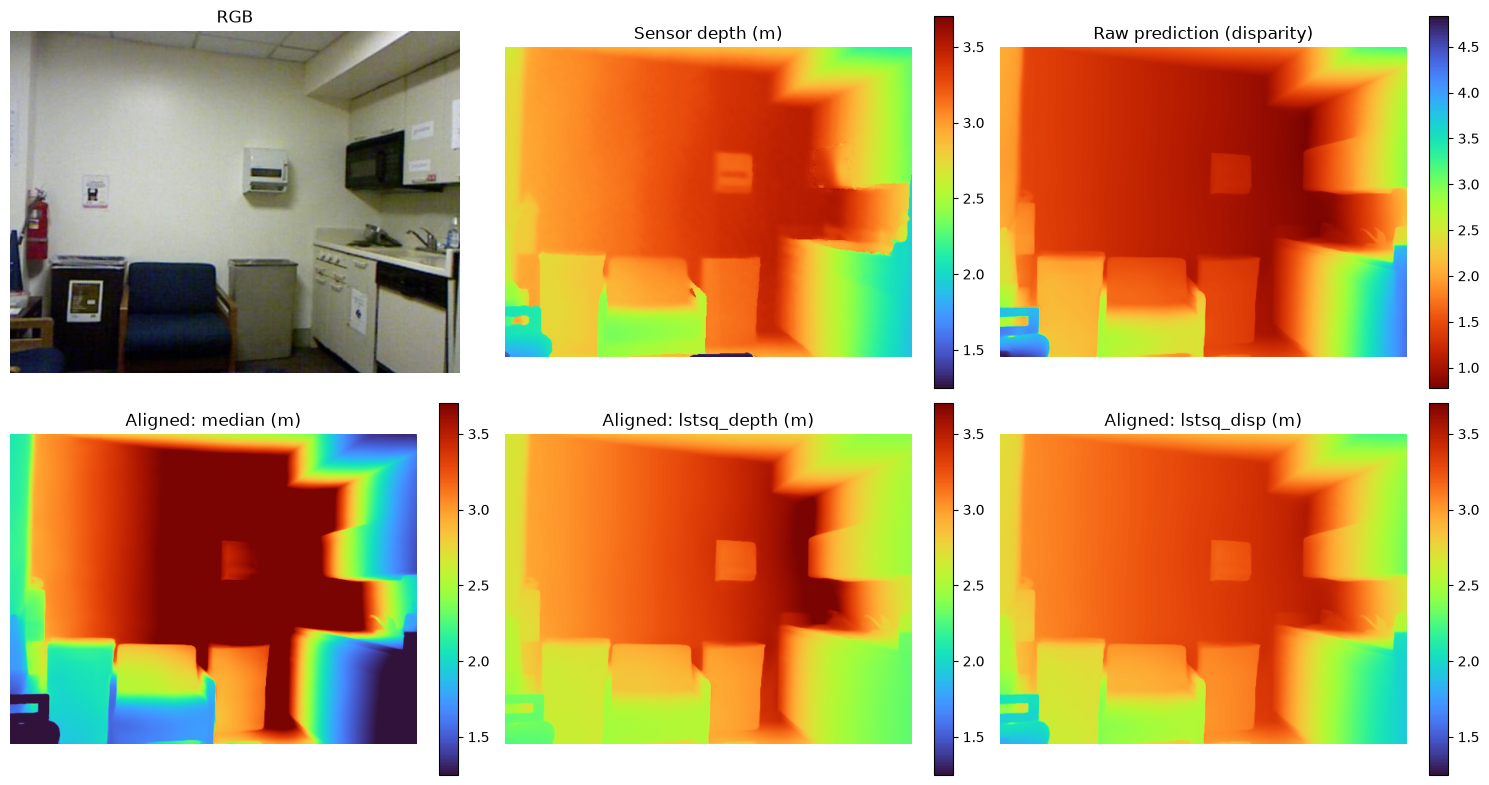

In [7]:
rgb = np.array(Image.open(DATASET_ROOT / sample["file_name"]).convert("RGB"))
vmin, vmax = sample_gt[v].min(), sample_gt[v].max()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0, 0].imshow(rgb); axes[0, 0].set_title("RGB")
im = axes[0, 1].imshow(np.where(v, sample_gt, np.nan), cmap="turbo", vmin=vmin, vmax=vmax)
axes[0, 1].set_title("Sensor depth (m)"); fig.colorbar(im, ax=axes[0, 1], fraction=0.046)
im = axes[0, 2].imshow(sample_raw, cmap="turbo_r")
axes[0, 2].set_title("Raw prediction (disparity)"); fig.colorbar(im, ax=axes[0, 2], fraction=0.046)
for ax, method in zip(axes[1], METHODS):
    im = ax.imshow(np.where(sample_aligned[method] > 0, sample_aligned[method], np.nan),
                   cmap="turbo", vmin=vmin, vmax=vmax)
    ax.set_title(f"Aligned: {method} (m)"); fig.colorbar(im, ax=ax, fraction=0.046)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / f"sample_{sample['id']}_alignment.png", dpi=150, bbox_inches="tight")
plt.show()

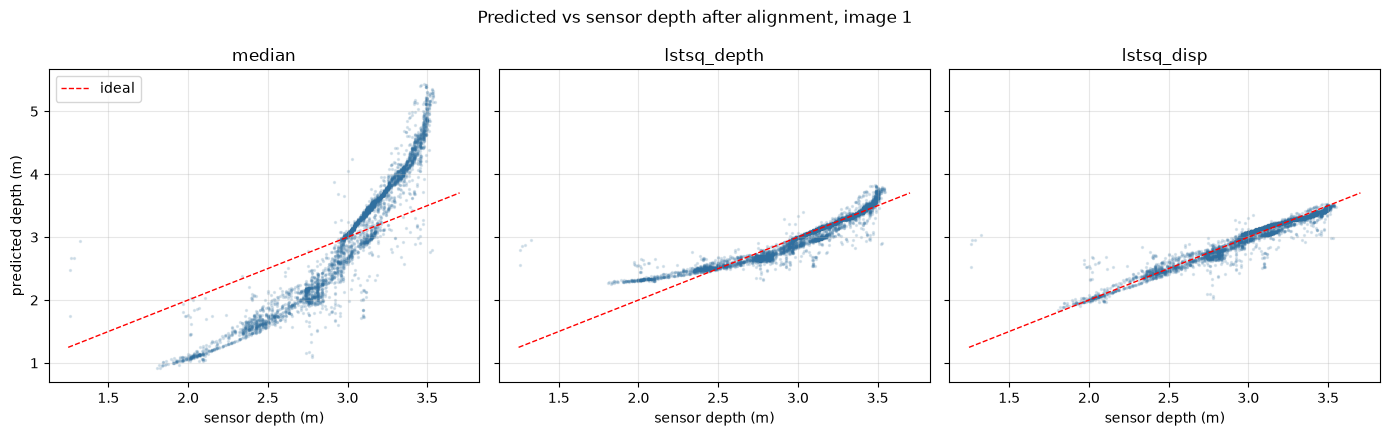

In [8]:
# scatter: predicted vs sensor depth (subsampled pixels), one panel per method
idx = np.random.default_rng(42).choice(int(v.sum()), size=min(4000, int(v.sum())), replace=False)
gt_pts = sample_gt[v][idx]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True)
for ax, method in zip(axes, METHODS):
    ax.scatter(gt_pts, sample_aligned[method][v][idx], s=2, alpha=0.15, color="#2f6f9f")
    ax.plot([vmin, vmax], [vmin, vmax], "r--", lw=1, label="ideal")
    ax.set_title(method); ax.set_xlabel("sensor depth (m)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("predicted depth (m)"); axes[0].legend()
plt.suptitle(f"Predicted vs sensor depth after alignment, image {sample['id']}")
plt.tight_layout()
plt.savefig(OUT_DIR / f"sample_{sample['id']}_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Global alignment fitted on validation

Per-image alignment needs the sensor map of *that* image at test time — it measures
the model's best possible geometry, but is not deployable. A single global transform
fitted once on the validation split is: it can be shipped with the model and applied
to a lone RGB frame.

The global parameters are the **median of per-image fits** over validation images —
more robust than pooling all pixels, which would let large images and near-field
surfaces dominate. Both variants are evaluated below; the gap between them is the
price of not knowing the scene scale.

In [9]:
fit_rows = []
val_subset = val_images[:N_FIT_VAL]
t0 = time.time()
for n, info in enumerate(val_subset, 1):
    gt, raw = load_gt(info), predict_raw(info)
    if valid_mask(gt).sum() < 1000:
        continue
    fit_rows.append({"sensor": info["sensor"],
                     **{f"{m}_{k}": p for m in METHODS
                        for k, p in zip(("p1", "p2"), fit_alignment(raw, gt, m))}})
    if n % 25 == 0 or n == len(val_subset):
        print(f"  fitted on {n}/{len(val_subset)} val images "
              f"({n / (time.time() - t0):.2f} img/s)", end="\r")
print()

fit_df = pd.DataFrame(fit_rows)
GLOBAL_PARAMS = {m: (float(fit_df[f"{m}_p1"].median()), float(fit_df[f"{m}_p2"].median()))
                 for m in METHODS}
print(f"Global alignment from {len(fit_df)} validation images:")
for m, (p1, p2) in GLOBAL_PARAMS.items():
    spread = fit_df[f"{m}_p1"].quantile([0.25, 0.75]).values
    print(f"  {m:12s} p1={p1:9.4f}  p2={p2:8.4f}   (p1 IQR: {spread[0]:.3f}–{spread[1]:.3f})")

  fitted on 150/150 val images (9.28 img/s)
Global alignment from 150 validation images:
  median       p1=   5.0914  p2=  0.0000   (p1 IQR: 4.161–6.099)
  lstsq_depth  p1=   1.1085  p2=  1.8662   (p1 IQR: 0.691–1.545)
  lstsq_disp   p1=   0.0861  p2=  0.2090   (p1 IQR: 0.068–0.110)


---
## Test-set evaluation

Every method is evaluated per-image and globally on the same pixels. The aligned
depth of the best per-image method is stored as `.npy` (float16) for the first
`N_SAVE` images — the input for the monocular point clouds in chapter 3.

In [10]:
eval_subset = test_images if N_EVAL is None else test_images[:N_EVAL]
save_ids = {im["id"] for im in eval_subset[:N_SAVE]}
SAVE_METHOD = "lstsq_disp"     # per-image maps stored for the 3D stage

rows = []
t0 = time.time()
for n, info in enumerate(eval_subset, 1):
    gt, raw = load_gt(info), predict_raw(info)
    if valid_mask(gt).sum() < 1000:
        continue
    base = {"image_id": info["id"], "sensor": info["sensor"],
            "scene_type": info["scene_type"], "median_gt_depth": float(np.median(gt[valid_mask(gt)]))}
    for method in METHODS:
        z_img = apply_alignment(raw, fit_alignment(raw, gt, method), method)
        rows.append({**base, "method": method, "alignment": "per_image",
                     **depth_metrics(z_img, gt)})
        z_glob = apply_alignment(raw, GLOBAL_PARAMS[method], method)
        rows.append({**base, "method": method, "alignment": "global",
                     **depth_metrics(z_glob, gt)})
        if method == SAVE_METHOD and info["id"] in save_ids:
            np.save(MAP_DIR / f"{info['id']}.npy", z_img.astype(np.float16))
    if n % 25 == 0 or n == len(eval_subset):
        print(f"  {n}/{len(eval_subset)} images ({n / (time.time() - t0):.2f} img/s, "
              f"ETA {(len(eval_subset) - n) / max(n / (time.time() - t0), 1e-6) / 60:.0f} min)",
              end="\r")
print()

depth_df = pd.DataFrame(rows)
depth_df.to_csv(OUT_DIR / "depth_metrics_per_image.csv", index=False)
print(f"Evaluated {depth_df.image_id.nunique()} images in {(time.time() - t0) / 60:.1f} min")
print(f"Saved {len(list(MAP_DIR.glob('*.npy')))} aligned depth maps ({SAVE_METHOD}) -> {MAP_DIR}")

  1325/1325 images (6.09 img/s, ETA 0 min)
Evaluated 1325 images in 3.6 min
Saved 1325 aligned depth maps (lstsq_disp) -> outputs/depth_mono/maps


In [11]:
# main comparison table: alignment method x alignment mode
COLS = ["abs_rel", "rmse", "rmse_log", "delta1", "delta2", "delta3"]
summary = (depth_df.groupby(["alignment", "method"])[COLS].mean()
           .reindex(pd.MultiIndex.from_product([["per_image", "global"], METHODS],
                                               names=["alignment", "method"])))
summary.to_csv(OUT_DIR / "depth_metrics_summary.csv")
print("Lower is better: abs_rel, rmse, rmse_log | higher is better: delta1-3\n")
summary.round(4)

Lower is better: abs_rel, rmse, rmse_log | higher is better: delta1-3



abs_rel    rmse  rmse_log  delta1  delta2  delta3
alignment method                                                        
per_image median        0.3841  1.4560    0.3964  0.5537  0.8036  0.9145
          lstsq_depth   0.2505  0.6649    0.2755  0.6708  0.8636  0.9435
          lstsq_disp    0.1163  0.4563    0.1688  0.8804  0.9507  0.9751
global    median        0.4987  1.6086    0.4778  0.3531  0.6620  0.8597
          lstsq_depth   0.4047  0.9557    0.3816  0.4806  0.7692  0.9061
          lstsq_disp    0.3099  0.7856    0.3086  0.5652  0.8379  0.9389

Best per-image method by AbsRel: lstsq_disp


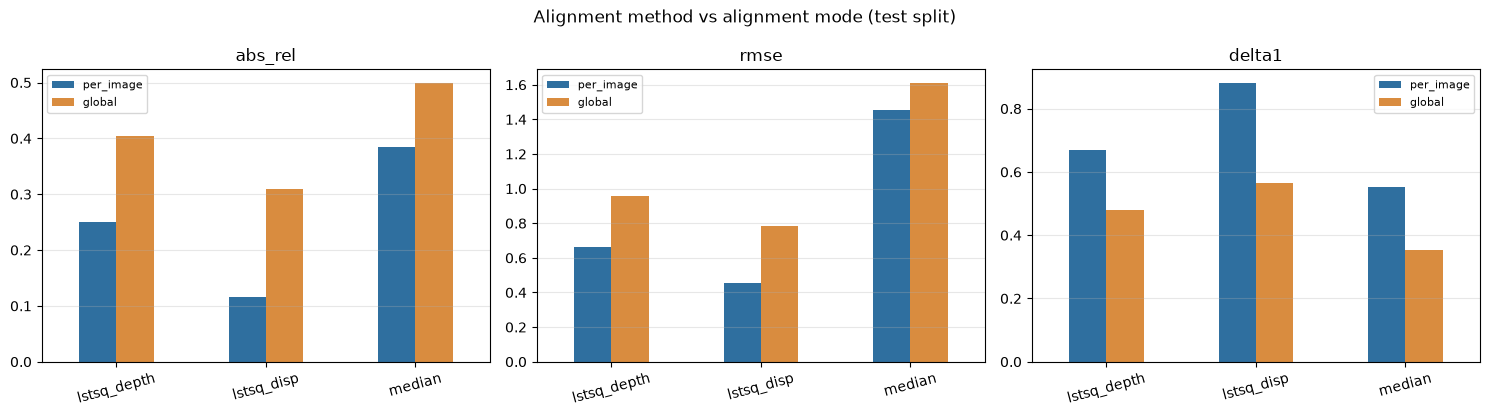

In [12]:
best = summary.loc["per_image", "abs_rel"].idxmin()
print(f"Best per-image method by AbsRel: {best}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, metric in zip(axes, ["abs_rel", "rmse", "delta1"]):
    pivot = summary[metric].unstack("alignment")[["per_image", "global"]]
    pivot.plot.bar(ax=ax, color=["#2f6f9f", "#d98c3f"], rot=15)
    ax.set_title(metric); ax.set_xlabel(""); ax.grid(axis="y", alpha=0.3)
    ax.legend(title="", fontsize=8)
plt.suptitle("Alignment method vs alignment mode (test split)")
plt.tight_layout()
plt.savefig(OUT_DIR / "alignment_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Error breakdown

Where the monocular model is weakest — the material for the discussion in 3.4.

In [13]:
sub = depth_df[(depth_df.method == best) & (depth_df.alignment == "per_image")].copy()

by_sensor = sub.groupby("sensor")[COLS + ["image_id"]].agg(
    {**{c: "mean" for c in COLS}, "image_id": "count"}).rename(columns={"image_id": "n_images"})
print(f"By sensor ({best}, per-image alignment):")
display(by_sensor.round(4))

sub["distance_bin"] = pd.cut(sub.median_gt_depth, [0, 1.5, 2.5, 3.5, 5.0, MAX_DEPTH],
                             labels=["<1.5 m", "1.5–2.5", "2.5–3.5", "3.5–5", ">5 m"])
by_distance = sub.groupby("distance_bin", observed=True)[COLS + ["image_id"]].agg(
    {**{c: "mean" for c in COLS}, "image_id": "count"}).rename(columns={"image_id": "n_images"})
print("\nBy scene distance (median sensor depth of the frame):")
display(by_distance.round(4))

by_sensor.to_csv(OUT_DIR / "depth_metrics_by_sensor.csv")
by_distance.to_csv(OUT_DIR / "depth_metrics_by_distance.csv")

By sensor (lstsq_disp, per-image alignment):


,abs_rel,rmse,rmse_log,delta1,delta2,delta3,n_images
sensor,,,,,,,
kv1,0.0970,0.4086,0.1419,0.9051,0.9679,0.9853,240
kv2,0.1388,0.5814,0.2040,0.8471,0.9292,0.9632,495
realsense,0.1828,0.5100,0.2484,0.7654,0.8988,0.9494,143
xtion,0.0804,0.3262,0.1188,0.9407,0.9818,0.9910,447



By scene distance (median sensor depth of the frame):


,abs_rel,rmse,rmse_log,delta1,delta2,delta3,n_images
distance_bin,,,,,,,
<1.5 m,0.0872,0.2554,0.1361,0.9211,0.9649,0.9858,110
1.5–2.5,0.1162,0.4233,0.1696,0.8801,0.9492,0.9743,824
2.5–3.5,0.1263,0.5784,0.1797,0.8658,0.9470,0.9720,317
3.5–5,0.1157,0.5855,0.1614,0.8873,0.9618,0.9809,69
>5 m,0.1313,0.8004,0.1732,0.8514,0.9590,0.9915,5


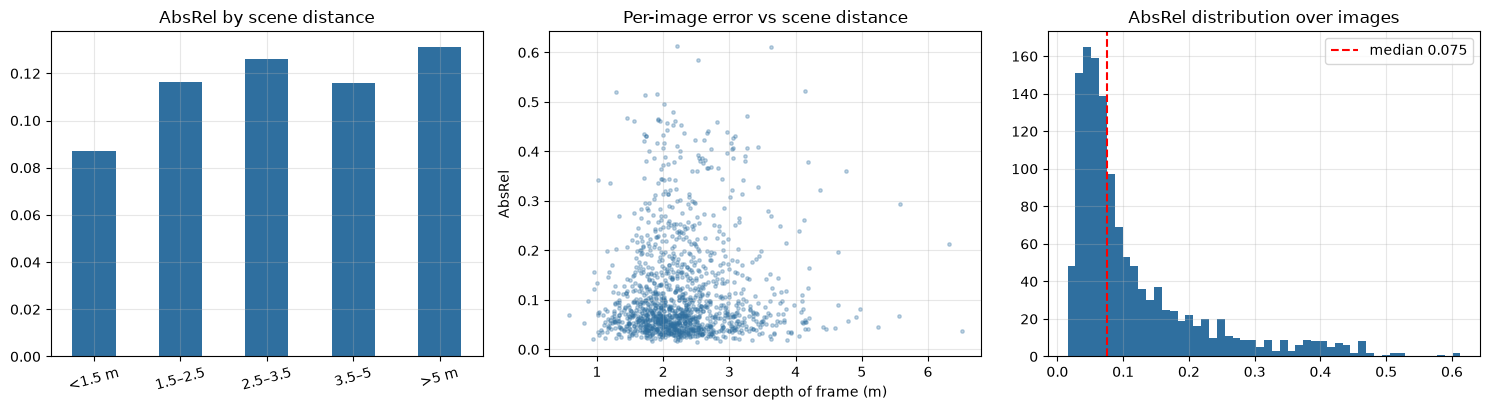

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
by_distance["abs_rel"].plot.bar(ax=axes[0], color="#2f6f9f", rot=15)
axes[0].set_title("AbsRel by scene distance"); axes[0].set_xlabel("")
axes[1].scatter(sub.median_gt_depth, sub.abs_rel, s=6, alpha=0.3, color="#2f6f9f")
axes[1].set_xlabel("median sensor depth of frame (m)"); axes[1].set_ylabel("AbsRel")
axes[1].set_title("Per-image error vs scene distance")
axes[2].hist(sub.abs_rel, bins=50, color="#2f6f9f")
axes[2].axvline(sub.abs_rel.median(), color="r", ls="--", label=f"median {sub.abs_rel.median():.3f}")
axes[2].set_title("AbsRel distribution over images"); axes[2].legend()
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "error_breakdown.png", dpi=150, bbox_inches="tight")
plt.show()

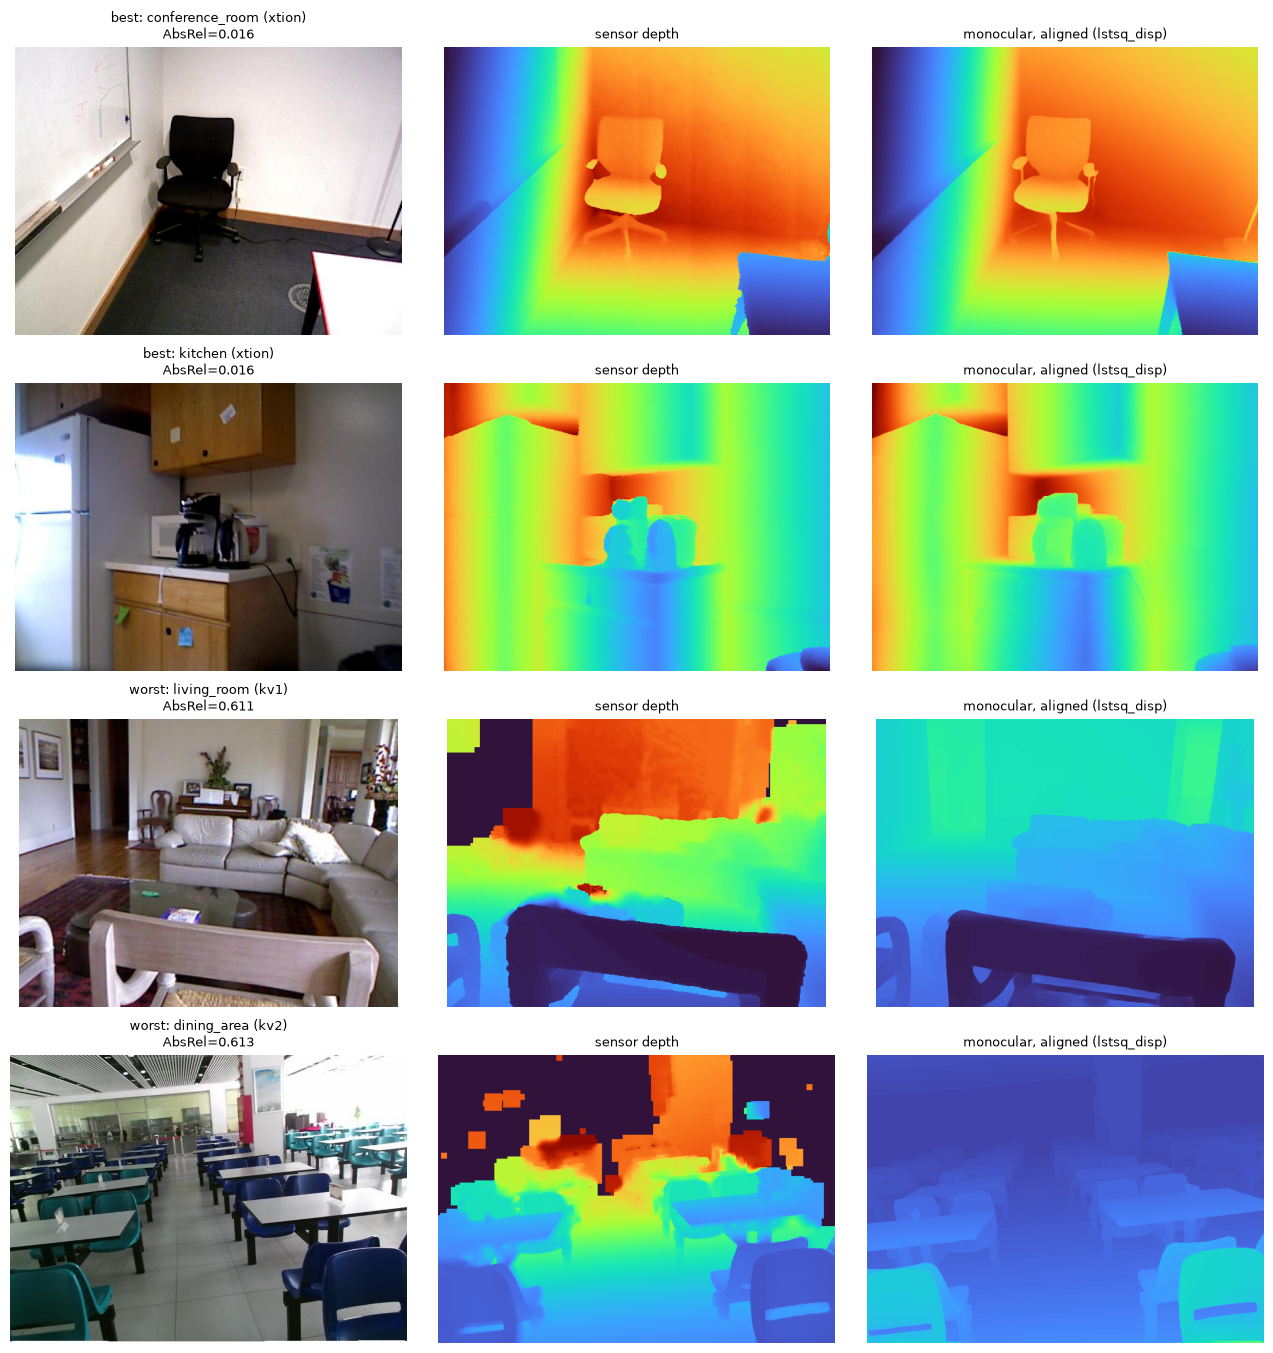

In [15]:
# qualitative extremes: the two easiest and the two hardest frames
ranked = sub.sort_values("abs_rel")
picks = [("best", r) for _, r in ranked.head(2).iterrows()] + \
        [("worst", r) for _, r in ranked.tail(2).iterrows()]
by_id = {im["id"]: im for im in test_images}

fig, axes = plt.subplots(len(picks), 3, figsize=(13, 3.4 * len(picks)))
for row, (label, rec) in zip(axes, picks):
    info = by_id[rec.image_id]
    gt, raw = load_gt(info), predict_raw(info)
    z = apply_alignment(raw, fit_alignment(raw, gt, best), best)
    vm = valid_mask(gt)
    lo, hi = gt[vm].min(), gt[vm].max()
    row[0].imshow(np.array(Image.open(DATASET_ROOT / info["file_name"]).convert("RGB")))
    row[0].set_title(f"{label}: {info['scene_type']} ({info['sensor']})\nAbsRel={rec.abs_rel:.3f}",
                     fontsize=9)
    row[1].imshow(np.where(vm, gt, np.nan), cmap="turbo", vmin=lo, vmax=hi)
    row[1].set_title("sensor depth", fontsize=9)
    row[2].imshow(np.where(z > 0, z, np.nan), cmap="turbo", vmin=lo, vmax=hi)
    row[2].set_title(f"monocular, aligned ({best})", fontsize=9)
    for ax in row: ax.axis("off")
plt.tight_layout()
plt.savefig(OUT_DIR / "qualitative_best_worst.png", dpi=150, bbox_inches="tight")
plt.show()

---
## Inference timing

Measured the same way as the segmentation models (batch 1, warmup + timed runs), so
the depth stage can be added to the end-to-end budget of the pipeline. These are MPS
numbers — the comparison table in 2.3 uses T4 timings and these must not be mixed
into it.

In [16]:
timing_img = Image.open(DATASET_ROOT / test_images[0]["file_name"]).convert("RGB")
timing_inputs = processor(images=timing_img, return_tensors="pt").to(DEVICE)

for _ in range(10):                                   # warmup
    with torch.no_grad():
        model(**timing_inputs)
if DEVICE == "mps":
    torch.mps.synchronize()

times = []
for _ in range(50):
    t = time.perf_counter()
    with torch.no_grad():
        model(**timing_inputs)
    if DEVICE == "mps":
        torch.mps.synchronize()
    times.append((time.perf_counter() - t) * 1000)

times = np.array(times)
print(f"{MODEL_ID} on {DEVICE}, batch 1, 10 warmup + 50 runs:")
print(f"  mean {times.mean():.1f} ms | median {np.median(times):.1f} ms | "
      f"std {times.std():.1f} ms | {1000 / times.mean():.1f} img/s")

depth-anything/Depth-Anything-V2-Small-hf on mps, batch 1, 10 warmup + 50 runs:
  mean 37.8 ms | median 37.0 ms | std 1.7 ms | 26.5 img/s


---
## Notes and limitations

- **Relative, not metric.** The model outputs disparity up to an unknown affine
  transform; every number above exists only after alignment against sensor depth.
  Reporting monocular depth in metres without stating the alignment protocol would be
  meaningless — this is the central methodological caveat of chapter 3.
- **Per-image alignment is an oracle.** It uses the sensor map of the very frame
  being evaluated, so it upper-bounds the achievable geometry. The global variant is
  what a deployed application could actually use; the gap between the two rows is the
  honest cost of scale ambiguity and belongs in the text.
- **Sensor depth is not perfect ground truth.** `depth_bfx` is inpainted and still
  fails on glossy, transparent and distant surfaces. Errors there are shared between
  the two maps, so metrics are computed only on valid sensor pixels — the monocular
  model is in fact never scored on the regions where it is most likely to invent
  plausible geometry.
- **Frame-level distance binning.** The breakdown uses the median depth of the frame,
  not per-object distance; per-object analysis follows in the point-cloud stage where
  instance masks are available.
- **Throughput.** Steady-state inference is ~12 img/s on MPS (whole test split in
  ~2 min). The 2026-08-14 run took far longer because other applications had the
  machine near zero free RAM and it swapped; `predict_raw` now releases the MPS cache
  each call, but a heavily loaded machine will still slow this notebook down.
- **Model size.** The Small checkpoint was chosen for local MPS inference and for the
  CPU-bound web demo. Larger variants would score better; that trade-off is a
  deliberate deployment decision, not an oversight.